# Вакуумные Пройдохи — экономика игрока

**Вопрос:** захватывает ли игра на 30–90 минут? Есть ли всегда цель?

Параметры из `src/config/balance.ts` и `src/systems/equipment/GearCatalog.ts` после Tasks 1–7.

**Шкала времени:** 1 минута игры ≈ 10 игровых дней (средняя скорость).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import FuncFormatter
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.family'] = 'monospace'
BG  = '#0d1117'
FIG = '#161b22'
GRID = '#21262d'

# ── Константы из balance.ts ────────────────────────────────────────────────
STARTING_MONEY        = 1000
QUEST_BASE_REWARD     = 400
QUEST_PER_JUMP        = 220
ARTIFACT_DROP_CHANCE  = 0.40
ARTIFACT_MIN, ARTIFACT_MAX = 1, 3
UPGRADE_COST_1 = 2   # первый апгрейд (+1 тех) = 2 арт.
UPGRADE_COST_2 = 5   # второй апгрейд (+2 тех) = 2+3 арт. суммарно
KILL_REP_DELTA = -10  # CombatScene.ts:30

# ── Квестовый микс (активный игрок) ───────────────────────────────────────
MIX_HOPS  = {1: 0.55, 2: 0.35, 3: 0.10}
MIX_TYPES = {'DELIVERY': (1.0, 0.50), 'BOUNTY': (1.6, 0.30), 'PATROL': (1.2, 0.20)}
QUESTS_PER_DAY = 1 / 12   # 1 квест каждые 12 дней

AVG_REWARD = sum(
    MIX_HOPS[h] * w * (QUEST_BASE_REWARD + QUEST_PER_JUMP * h) * mult
    for h in MIX_HOPS
    for (mult, w) in MIX_TYPES.values()
)
print(f'Средняя награда за квест: {AVG_REWARD:.0f} кр.')

# ── Снаряжение из GearCatalog.ts ──────────────────────────────────────────
# (id, name, kind, techLevel, basePrice)
GEAR = [
    ('hull_corvette_mk1',  'Корвет Mk-I',     'HULL',   2, 1200),
    ('hull_cruiser_mk1',   'Крейсер Mk-I',    'HULL',   3, 3000),
    ('hull_corvette_mk2',  'Корвет Mk-II',    'HULL',   3, 2500),
    ('hull_dreadnought',   'Дредноут',        'HULL',   5, 7000),
    ('hull_frigate_mk1',   'Фрегат Mk-I',     'HULL',   4, 4500),
    ('hull_titan',         'Титан',           'HULL',   7,12000),
    ('wpn_laser_mk1',      'Лазер Mk-I',      'WEAPON', 2,  800),
    ('wpn_plasma_mk1',     'Плазма Mk-I',     'WEAPON', 5, 7500),
    ('wpn_rail_mk1',       'Рейлган Mk-I',    'WEAPON', 4, 3800),
    ('wpn_laser_mk2',      'Лазер Mk-II',     'WEAPON', 3, 2200),
    ('wpn_antimatter',     'Антиматерия',     'WEAPON', 6, 8500),
    ('wpn_plasma_mk2',     'Плазма Mk-II',    'WEAPON', 3, 2500),
    ('eng_basic',          'Двигатель Mk-I',  'ENGINE', 2,  900),
    ('eng_warp_mk1',       'Варп-двигатель',  'ENGINE', 5, 6500),
    ('eng_ion',            'Ионный',          'ENGINE', 1,  500),
    ('eng_fusion',         'Термоядерный',    'ENGINE', 4, 2800),
    ('eq_shield_mk1',      'Щит Mk-I',        'EQUIP',  4, 2600),
    ('eq_shield_mk2',      'Щит Mk-II',       'EQUIP',  5, 6000),
    ('eq_cloak',           'Маскировка',      'EQUIP',  6, 7800),
]

def best_gear_at_tech(max_tech):
    available = [g for g in GEAR if g[3] <= max_tech]
    if not available: return None
    best_hull   = max((g for g in available if g[2]=='HULL'),   key=lambda g: g[3], default=None)
    best_weapon = max((g for g in available if g[2]=='WEAPON'), key=lambda g: g[3], default=None)
    return best_hull, best_weapon

# ── Технологическое развитие систем ────────────────────────────────────────
# RESEARCH_LAB: +1 каждые 50 дней; обычная: +1 каждые 100 дней
def tech_at_day(day, is_research_lab=True):
    interval = 50 if is_research_lab else 100
    return min(8, 1 + day // interval)

print('OK — константы загружены')

Средняя награда за квест: 904 кр.
OK — константы загружены


## 1. Кривая накопления кредитов + доступность снаряжения

Три профиля игроков: **осторожный** (1 квест / 20 дней), **активный** (1 / 12), **хардкорный** (1 / 7 + боёвка).

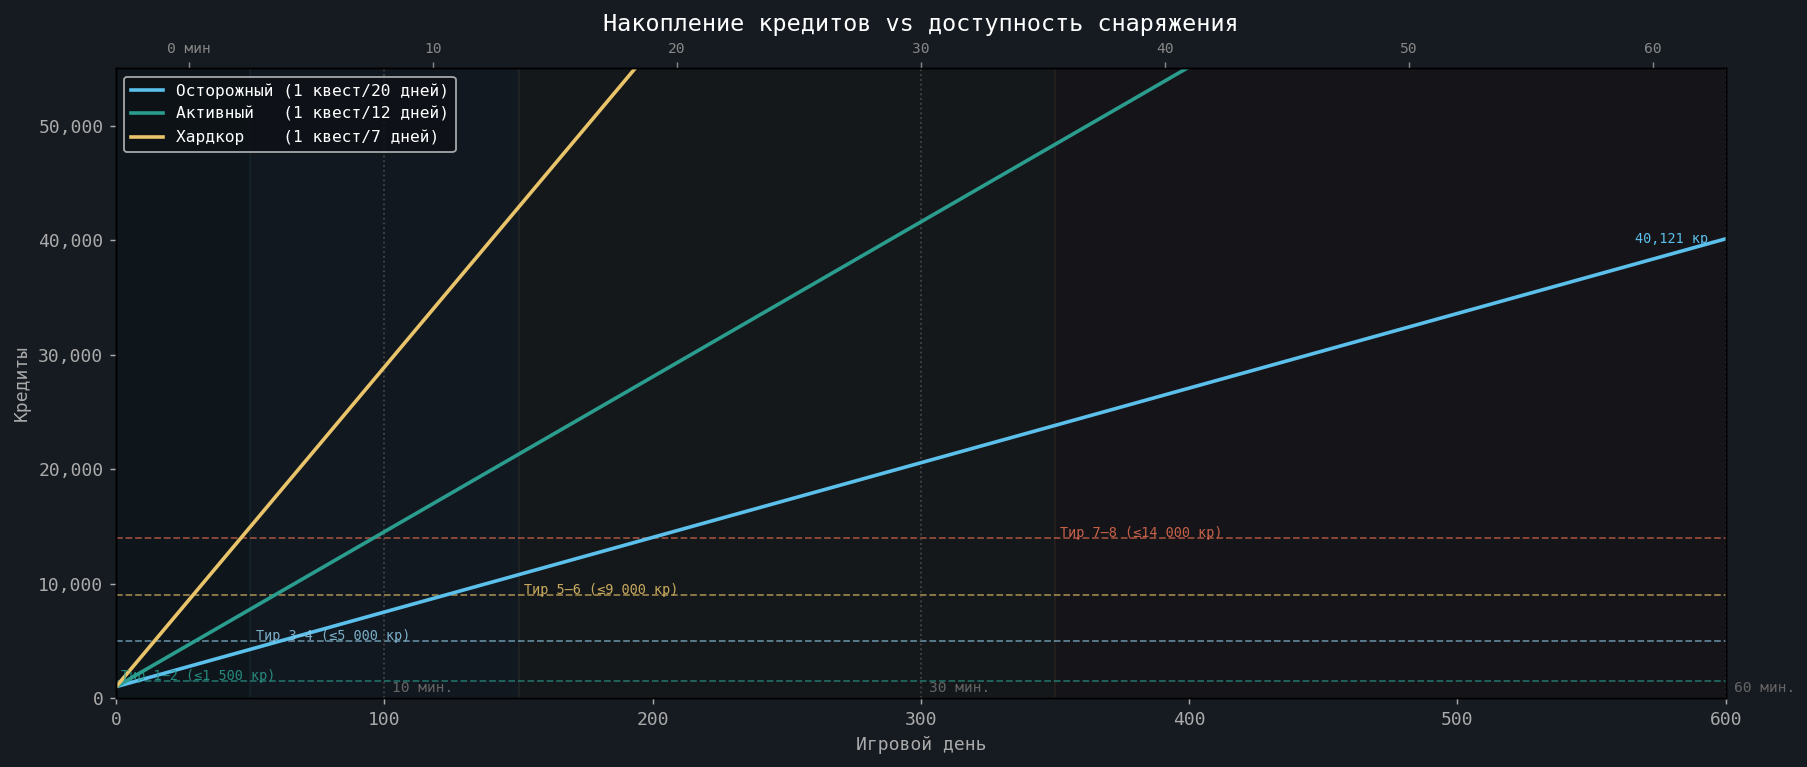

Активный игрок (1 квест/12 дней + боёвка):
  День  50 ( 5 мин) →   7,767 кр.  тех-доступ: 2 (lab), 1 (обычн.)
  День 100 (10 мин) →  14,534 кр.  тех-доступ: 3 (lab), 2 (обычн.)
  День 150 (15 мин) →  21,300 кр.  тех-доступ: 4 (lab), 2 (обычн.)
  День 250 (25 мин) →  34,834 кр.  тех-доступ: 6 (lab), 3 (обычн.)
  День 350 (35 мин) →  48,367 кр.  тех-доступ: 8 (lab), 4 (обычн.)
  День 500 (50 мин) →  68,668 кр.  тех-доступ: 8 (lab), 6 (обычн.)


In [2]:
DAYS = np.arange(0, 601)  # 600 дней = 60 минут
MIN  = DAYS / 10           # ось игрового времени в минутах

# Профили: (квестов/день, боевой доход кр/день, label, color)
PROFILES = [
    (1/20, 20,  'Осторожный (1 квест/20 дней)',  '#5bc0eb'),
    (1/12, 60,  'Активный   (1 квест/12 дней)',  '#2a9d8f'),
    (1/7,  150, 'Хардкор    (1 квест/7 дней)',   '#e9c46a'),
]

def credits_at_day(day, quest_rate, combat_income):
    return STARTING_MONEY + quest_rate * day * AVG_REWARD + combat_income * day

fig, ax = plt.subplots(figsize=(14, 6))
fig.patch.set_facecolor(FIG)
ax.set_facecolor(BG)

# Зоны доступности снаряжения (цена + техлвл)
# Ценовые полосы: до скольки нужно копить на каждый тир
TIER_BANDS = [
    (0,   50,  1500,  '#2a9d8f', 'Тир 1–2 (≤1 500 кр)'),
    (50,  150, 5000,  '#8ecae6', 'Тир 3–4 (≤5 000 кр)'),
    (150, 350, 9000,  '#e9c46a', 'Тир 5–6 (≤9 000 кр)'),
    (350, 600, 14000, '#e76f51', 'Тир 7–8 (≤14 000 кр)'),
]

for day_from, day_to, price, col, label in TIER_BANDS:
    ax.axhline(price, color=col, ls='--', lw=1.0, alpha=0.6)
    ax.axvspan(day_from, min(day_to, 600), alpha=0.04, color=col)
    ax.text(day_from + 2, price + 100, label, color=col, fontsize=7.5, alpha=0.85)

# Временны́е маркеры (минуты игры)
for mins, day in [(10, 100), (30, 300), (60, 600)]:
    ax.axvline(day, color='#444', ls=':', lw=1)
    ax.text(day + 3, 500, f'{mins} мин.', color='#666', fontsize=8)

# Кривые накопления
for quest_rate, combat_income, label, col in PROFILES:
    crds = [credits_at_day(d, quest_rate, combat_income) for d in DAYS]
    ax.plot(DAYS, crds, color=col, lw=2, label=label)
    # Аннотация на конце
    ax.annotate(f'{crds[-1]:,.0f} кр.', xy=(DAYS[-1], crds[-1]),
                xytext=(-5, 0), textcoords='offset points',
                color=col, fontsize=7.5, ha='right', va='center')

# Вторая ось X — минуты
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks([0, 100, 200, 300, 400, 500, 600])
ax2.set_xticklabels(['0 мин', '10', '20', '30', '40', '50', '60'], color='#888', fontsize=8)
ax2.set_facecolor(BG)
ax2.tick_params(colors='#888')

ax.set_xlabel('Игровой день', color='#aaa')
ax.set_ylabel('Кредиты', color='#aaa')
ax.set_title('Накопление кредитов vs доступность снаряжения', color='white', fontsize=13)
ax.tick_params(colors='#aaa')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend(loc='upper left', fontsize=9, facecolor=BG, labelcolor='white')
ax.set_xlim(0, 600)
ax.set_ylim(0, 55000)

plt.tight_layout()
plt.savefig('economy_credits.png', bbox_inches='tight')
plt.show()

print('Активный игрок (1 квест/12 дней + боёвка):')
for d in [50, 100, 150, 250, 350, 500]:
    c = credits_at_day(d, 1/12, 60)
    print(f'  День {d:3d} ({d//10:2d} мин) → {c:7,.0f} кр.  тех-доступ: {tech_at_day(d)} (lab), {tech_at_day(d, False)} (обычн.)')

## 2. Технологическое окно: что появляется в магазинах

Какие конкретные предметы становятся доступны когда?

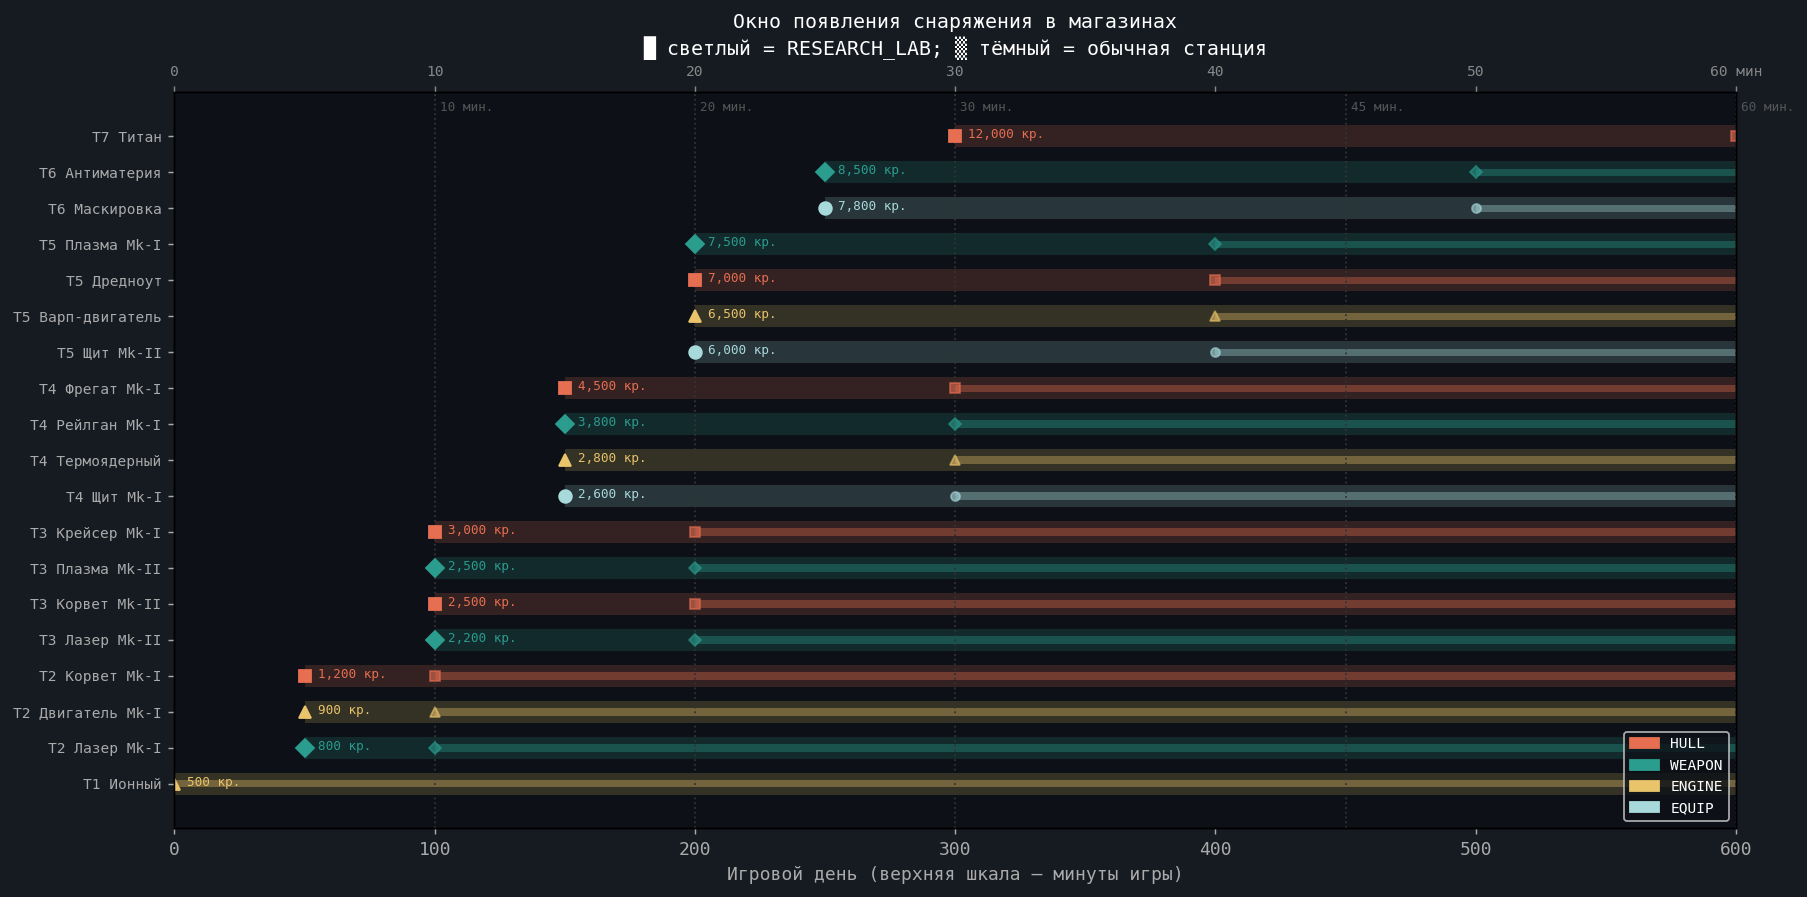

In [4]:
fig, ax = plt.subplots(figsize=(14, 7))
fig.patch.set_facecolor(FIG)
ax.set_facecolor(BG)

KIND_COLOR = {'HULL': '#e76f51', 'WEAPON': '#2a9d8f', 'ENGINE': '#e9c46a', 'EQUIP': '#a8dadc'}
KIND_MARKER = {'HULL': 's', 'WEAPON': 'D', 'ENGINE': '^', 'EQUIP': 'o'}

# Для каждого предмета: день появления в RESEARCH_LAB и в обычной системе
gear_sorted = sorted(GEAR, key=lambda g: (g[3], g[4]))

y_pos = 0
yticks, ylabels = [], []

for (gid, name, kind, tech, price) in gear_sorted:
    day_lab  = max(0, (tech - 1) * 50)   # RESEARCH_LAB
    day_norm = max(0, (tech - 1) * 100)  # обычная система
    col = KIND_COLOR[kind]

    # Горизонтальная полоса доступности
    ax.barh(y_pos, 600 - day_lab, left=day_lab, height=0.6,
            color=col, alpha=0.18)
    ax.barh(y_pos, 600 - day_norm, left=day_norm, height=0.2,
            color=col, alpha=0.35)

    # Маркеры появления
    ax.plot(day_lab,  y_pos, marker=KIND_MARKER[kind], color=col, ms=7, zorder=5)
    ax.plot(day_norm, y_pos, marker=KIND_MARKER[kind], color=col, ms=5, alpha=0.6, zorder=4)

    # Цена
    ax.text(day_lab + 5, y_pos + 0.05, f'{price:,} кр.', color=col, fontsize=7, va='center')

    yticks.append(y_pos)
    ylabels.append(f'T{tech} {name}')
    y_pos += 1

# Минутные маркеры
for mins, day in [(10, 100), (20, 200), (30, 300), (45, 450), (60, 600)]:
    ax.axvline(day, color='#333', ls=':', lw=1)
    ax.text(day + 2, y_pos - 0.3, f'{mins} мин.', color='#555', fontsize=7)

ax.set_yticks(yticks)
ax.set_yticklabels(ylabels, fontsize=8, color='#ccc')
ax.set_xlabel('Игровой день (верхняя шкала — минуты игры)', color='#aaa')
ax.set_title('Окно появления снаряжения в магазинах\n█ светлый = RESEARCH_LAB; ▒ тёмный = обычная станция', color='white', fontsize=11)
ax.tick_params(colors='#aaa')
ax.set_xlim(0, 600)

# Вторая ось X — минуты
ax2 = ax.twiny()
ax2.set_xlim(ax.get_xlim())
ax2.set_xticks([0, 100, 200, 300, 400, 500, 600])
ax2.set_xticklabels(['0', '10', '20', '30', '40', '50', '60 мин'], color='#888', fontsize=8)
ax2.tick_params(colors='#888')

# Легенда типов
patches = [mpatches.Patch(color=v, label=k) for k, v in KIND_COLOR.items()]
ax.legend(handles=patches, loc='lower right', fontsize=8, facecolor=BG, labelcolor='white')

plt.tight_layout()
plt.savefig('economy_tech_window.png', bbox_inches='tight')
plt.show()

## 3. Доступность: могу ли я купить? (кредиты vs цена)

Отношение `накопленных кредитов / цена лучшего снаряжения тека` показывает,
когда игрок впервые может позволить себе апгрейд.

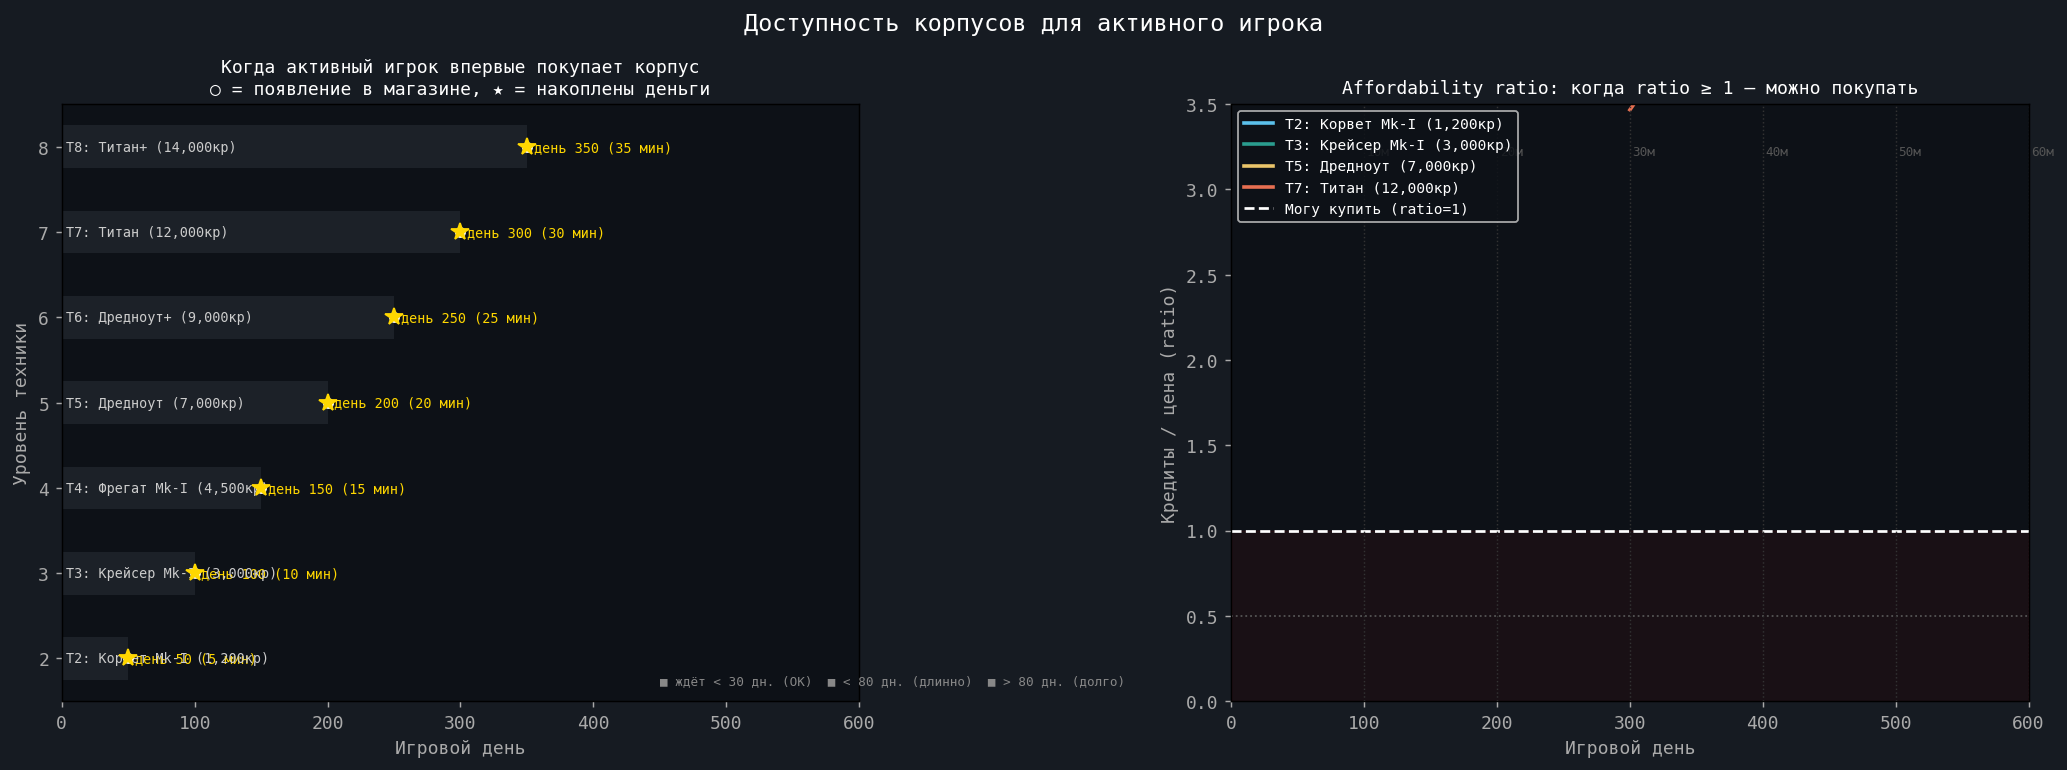

In [6]:
# Лучшие корпуса по уровню техники
HULLS_BY_TECH = {
    1: ('Корвет (старт)', 0),       # стартовый
    2: ('Корвет Mk-I',  1200),
    3: ('Крейсер Mk-I', 3000),
    4: ('Фрегат Mk-I',  4500),
    5: ('Дредноут',     7000),
    6: ('Дредноут+',    9000),      # апгрейд артефактами
    7: ('Титан',       12000),
    8: ('Титан+',      14000),      # максимальный апгрейд
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor(FIG)

# --- Левый: когда впервые можно купить каждый корпус ---
ax = axes[0]
ax.set_facecolor(BG)

quest_rate, combat = 1/12, 60  # активный профиль

for tech, (hull_name, hull_price) in HULLS_BY_TECH.items():
    if hull_price == 0: continue
    day_avail = max(0, (tech - 1) * 50)    # RESEARCH_LAB появление
    # День когда накопятся деньги (с учётом трат на прошлый корпус)
    # упрощение: считаем от чистого накопления
    for d in DAYS:
        if d >= day_avail and credits_at_day(d, quest_rate, combat) >= hull_price:
            can_afford_day = d
            break
    else:
        can_afford_day = 999
    
    wait = max(0, can_afford_day - day_avail)
    color = '#2a9d8f' if wait < 30 else '#e9c46a' if wait < 80 else '#e76f51'
    ax.barh(tech, wait, left=day_avail, height=0.5, color=color, alpha=0.8)
    ax.barh(tech, day_avail, left=0, height=0.5, color='#21262d', alpha=0.8)
    ax.plot(day_avail, tech, 'o', color='white', ms=5, zorder=5)
    if can_afford_day < 999:
        ax.plot(can_afford_day, tech, '*', color='#ffd700', ms=10, zorder=6)
        ax.text(can_afford_day + 5, tech, f'день {can_afford_day} ({can_afford_day//10} мин)',
                color='#ffd700', fontsize=7.5, va='center')
    ax.text(3, tech, f'T{tech}: {hull_name} ({hull_price:,}кр)', color='#ccc', fontsize=7.5, va='center')

ax.set_xlabel('Игровой день', color='#aaa')
ax.set_ylabel('Уровень техники', color='#aaa')
ax.set_title('Когда активный игрок впервые покупает корпус\n○ = появление в магазине, ★ = накоплены деньги', color='white', fontsize=10)
ax.tick_params(colors='#aaa')
ax.set_xlim(0, 600)
ax.set_ylim(1.5, 8.5)
# Цветовые подсказки
ax.text(450, 1.7, '■ ждёт < 30 дн. (OK)  ■ < 80 дн. (длинно)  ■ > 80 дн. (долго)',
        color='#888', fontsize=7)

# --- Правый: affordability ratio по времени ---
ax2 = axes[1]
ax2.set_facecolor(BG)

MILESTONE_HULLS = [
    (1200, 2, 'Корвет Mk-I',  '#5bc0eb'),
    (3000, 3, 'Крейсер Mk-I', '#2a9d8f'),
    (7000, 5, 'Дредноут',     '#e9c46a'),
    (12000,7, 'Титан',        '#e76f51'),
]

for price, tech, name, col in MILESTONE_HULLS:
    day_avail = (tech - 1) * 50
    ratios = []
    for d in DAYS:
        if d < day_avail:
            ratios.append(None)
        else:
            ratios.append(credits_at_day(d, quest_rate, combat) / price)
    # Только где не None
    valid_days   = [d for d, r in zip(DAYS, ratios) if r is not None]
    valid_ratios = [r for r in ratios if r is not None]
    ax2.plot(valid_days, valid_ratios, color=col, lw=2, label=f'T{tech}: {name} ({price:,}кр)')

ax2.axhline(1.0, color='white', ls='--', lw=1.5, label='Могу купить (ratio=1)')
ax2.axhline(0.5, color='#555', ls=':', lw=1)
ax2.fill_between(DAYS, 0, 1, alpha=0.05, color='red')

# Минутные маркеры
for mins in [10, 20, 30, 40, 50, 60]:
    ax2.axvline(mins * 10, color='#333', ls=':', lw=0.8)
    ax2.text(mins * 10 + 2, 3.2, f'{mins}м', color='#555', fontsize=7)

ax2.set_xlabel('Игровой день', color='#aaa')
ax2.set_ylabel('Кредиты / цена (ratio)', color='#aaa')
ax2.set_title('Affordability ratio: когда ratio ≥ 1 — можно покупать', color='white', fontsize=10)
ax2.legend(fontsize=8, facecolor=BG, labelcolor='white', loc='upper left')
ax2.tick_params(colors='#aaa')
ax2.set_xlim(0, 600)
ax2.set_ylim(0, 3.5)

plt.suptitle('Доступность корпусов для активного игрока', color='white', fontsize=13)
plt.tight_layout()
plt.savefig('economy_affordability.png', bbox_inches='tight')
plt.show()

## 4. Артефактная экономика: время до апгрейда

Игрок охотится на корабли Оверминда. 40% шанс 1–3 артефактов за убийство.
Апгрейд снаряжения: 2 арт. → +1 тех, 5 арт. суммарно → +2 теха.

Медиана убийств Оверминда для +1 тех: 3  (p5=1, p95=8)
Медиана убийств Оверминда для +2 тех: 6  (p5=2, p95=14)


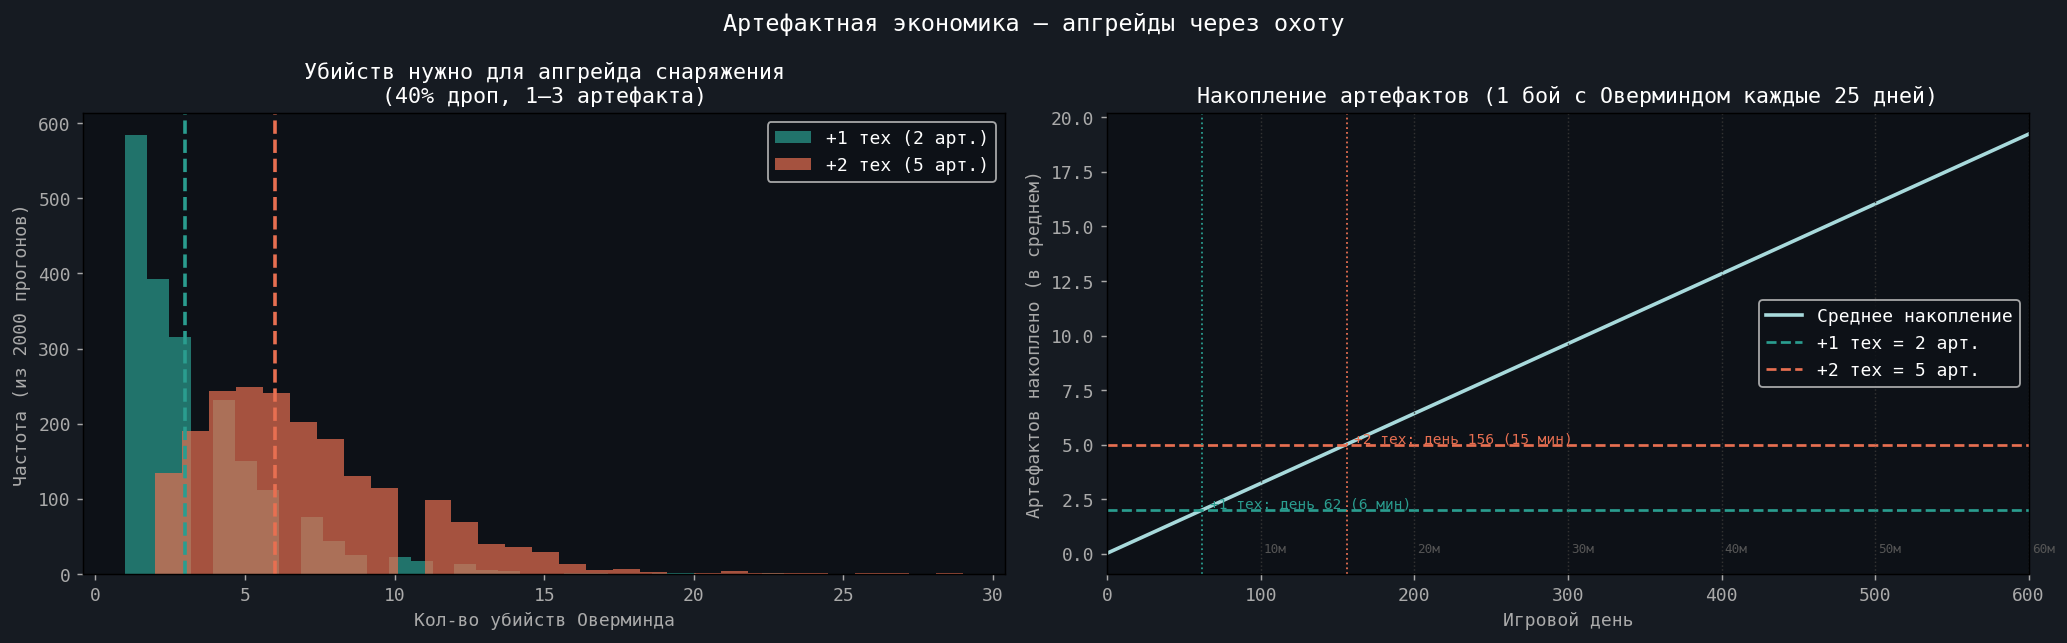

In [7]:
import numpy as np

def simulate_artifacts(n_kills, drop_chance=0.40, min_drop=1, max_drop=3, seed=42):
    rng = np.random.default_rng(seed)
    total = 0
    for _ in range(n_kills):
        if rng.random() < drop_chance:
            total += rng.integers(min_drop, max_drop + 1)
    return total

# Симуляция 1000 прогонов: сколько убийств нужно для 2 артефактов (апгрейд 1)
N_RUNS = 2000
kills_for_upgrade1 = []
kills_for_upgrade2 = []

rng_master = np.random.default_rng(42)
for run in range(N_RUNS):
    total, k = 0, 0
    k1, k2 = None, None
    while total < UPGRADE_COST_2 + 1:  # чуть больше чем нужно
        if rng_master.random() < ARTIFACT_DROP_CHANCE:
            total += rng_master.integers(ARTIFACT_MIN, ARTIFACT_MAX + 1)
        k += 1
        if k1 is None and total >= UPGRADE_COST_1:
            k1 = k
        if k2 is None and total >= UPGRADE_COST_2:
            k2 = k
            break
    kills_for_upgrade1.append(k1 or k)
    kills_for_upgrade2.append(k2 or k)

print(f'Медиана убийств Оверминда для +1 тех: {np.median(kills_for_upgrade1):.0f}  (p5={np.percentile(kills_for_upgrade1,5):.0f}, p95={np.percentile(kills_for_upgrade1,95):.0f})')
print(f'Медиана убийств Оверминда для +2 тех: {np.median(kills_for_upgrade2):.0f}  (p5={np.percentile(kills_for_upgrade2,5):.0f}, p95={np.percentile(kills_for_upgrade2,95):.0f})')

# Накопление артефактов по дням (через бои)
# Предположим: игрок попадает в бой с Оверминдом раз в 20-30 дней
OVERMIND_FIGHTS_PER_DAY = 1 / 25  # 1 бой с овермайндом каждые 25 дней

artifact_accumulation_days = []
cum_art = 0
cum_fights = 0
for d in range(601):
    # В среднем: бои с Оверминдом
    cum_fights += OVERMIND_FIGHTS_PER_DAY
    cum_art += OVERMIND_FIGHTS_PER_DAY * ARTIFACT_DROP_CHANCE * (ARTIFACT_MIN + ARTIFACT_MAX) / 2
    artifact_accumulation_days.append(cum_art)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor(FIG)

# --- Левый: распределение убийств ---
ax = axes[0]
ax.set_facecolor(BG)
ax.hist(kills_for_upgrade1, bins=30, color='#2a9d8f', alpha=0.7, label='+1 тех (2 арт.)')
ax.hist(kills_for_upgrade2, bins=30, color='#e76f51', alpha=0.7, label='+2 тех (5 арт.)')
ax.axvline(np.median(kills_for_upgrade1), color='#2a9d8f', ls='--', lw=2)
ax.axvline(np.median(kills_for_upgrade2), color='#e76f51', ls='--', lw=2)
ax.set_xlabel('Кол-во убийств Оверминда', color='#aaa')
ax.set_ylabel('Частота (из 2000 прогонов)', color='#aaa')
ax.set_title('Убийств нужно для апгрейда снаряжения\n(40% дроп, 1–3 артефакта)', color='white')
ax.legend(facecolor=BG, labelcolor='white')
ax.tick_params(colors='#aaa')

# --- Правый: накопление артефактов по дням ---
ax2 = axes[1]
ax2.set_facecolor(BG)
ax2.plot(range(601), artifact_accumulation_days, color='#a8dadc', lw=2, label='Среднее накопление')
ax2.axhline(UPGRADE_COST_1, color='#2a9d8f', ls='--', lw=1.5, label=f'+1 тех = {UPGRADE_COST_1} арт.')
ax2.axhline(UPGRADE_COST_2, color='#e76f51', ls='--', lw=1.5, label=f'+2 тех = {UPGRADE_COST_2} арт.')

# День когда накапливается нужное количество
for cost, label, col in [(UPGRADE_COST_1, '+1 тех', '#2a9d8f'), (UPGRADE_COST_2, '+2 тех', '#e76f51')]:
    for d, art in enumerate(artifact_accumulation_days):
        if art >= cost:
            ax2.axvline(d, color=col, ls=':', lw=1)
            ax2.text(d + 5, cost + 0.1, f'{label}: день {d} ({d//10} мин)', color=col, fontsize=8)
            break

# Минутные маркеры
for mins in [10, 20, 30, 40, 50, 60]:
    ax2.axvline(mins * 10, color='#333', ls=':', lw=0.8)
    ax2.text(mins * 10 + 2, 0.05, f'{mins}м', color='#555', fontsize=7)

ax2.set_xlabel('Игровой день', color='#aaa')
ax2.set_ylabel('Артефактов накоплено (в среднем)', color='#aaa')
ax2.set_title(f'Накопление артефактов (1 бой с Оверминдом каждые 25 дней)', color='white')
ax2.legend(facecolor=BG, labelcolor='white')
ax2.tick_params(colors='#aaa')
ax2.set_xlim(0, 600)

plt.suptitle('Артефактная экономика — апгрейды через охоту', color='white', fontsize=13)
plt.tight_layout()
plt.savefig('economy_artifacts.png', bbox_inches='tight')
plt.show()

## 5. Репутационная кривая: насколько легко стать враждебным

При новых порогах: `Нейтральный ≥ -20`, `Недовольный ≥ -50`, `Враждебный < -50`.

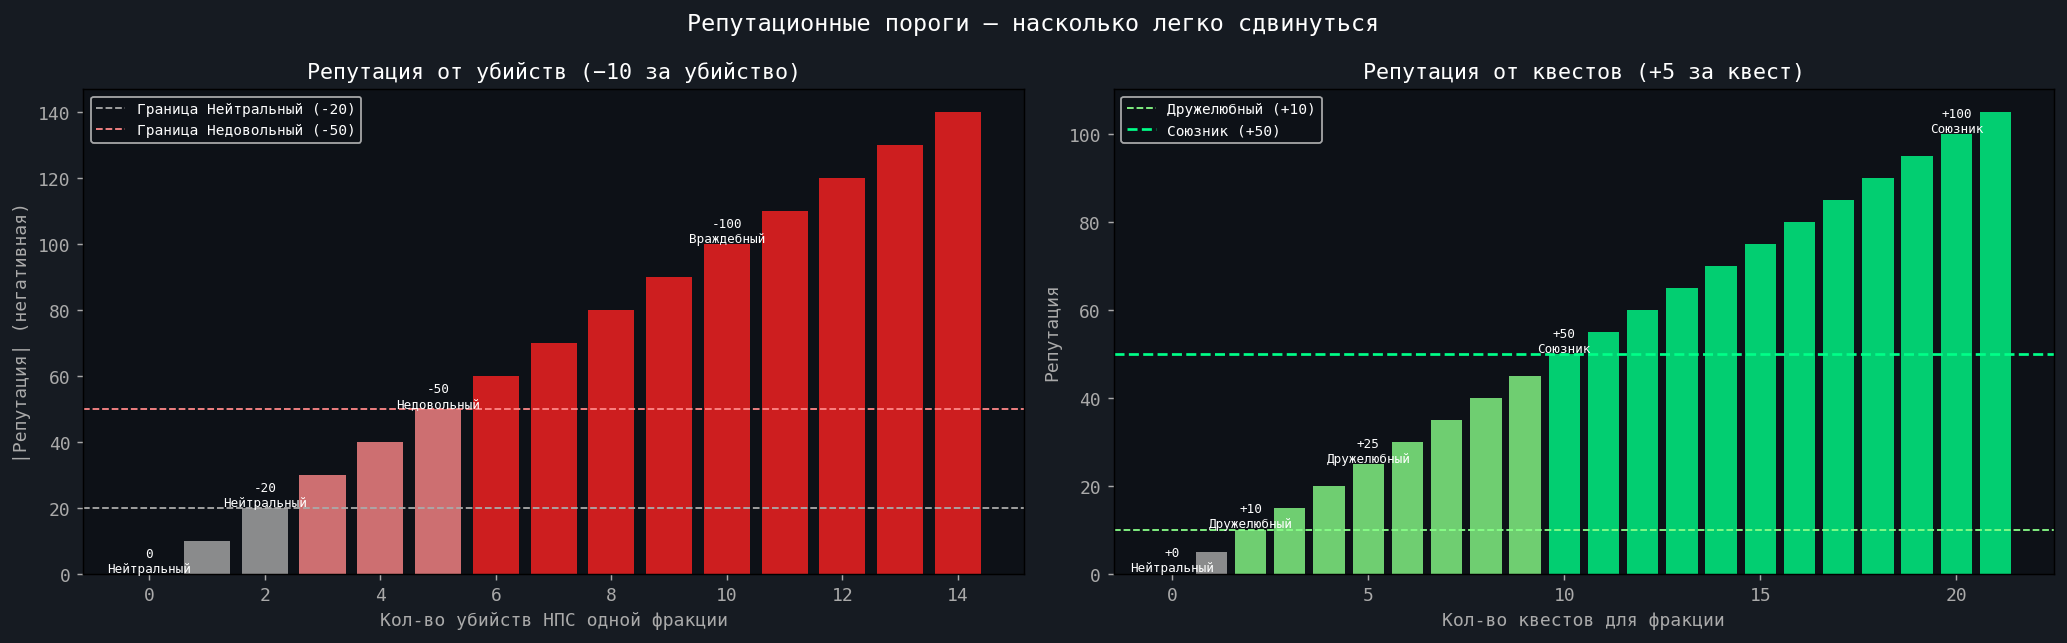

Репутационные пороги (новые):
  ≥   50: Союзник
  ≥   10: Дружелюбный
  ≥  -20: Нейтральный
  ≥  -50: Недовольный
  < -50: Враждебный

2 убийства НПС: репутация -20 → Нейтральный
5 убийств НПС:  репутация -50 → Недовольный
6 убийств НПС:  репутация -60 → Враждебный


In [8]:
def rep_label(r):
    if r >= 50:  return 'Союзник',    '#00ff88'
    if r >= 10:  return 'Дружелюбный','#88ff88'
    if r >= -20: return 'Нейтральный','#aaaaaa'
    if r >= -50: return 'Недовольный','#ff8888'
    return 'Враждебный', '#ff2222'

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor(FIG)

# --- Левый: лестница репутации от убийств ---
ax = axes[0]
ax.set_facecolor(BG)

kills_range = range(0, 15)
rep_values  = [0 + k * KILL_REP_DELTA for k in kills_range]
colors_rep  = [rep_label(r)[1] for r in rep_values]

bars = ax.bar(kills_range, [abs(r) for r in rep_values], color=colors_rep, alpha=0.8)
ax.axhline(20,  color='#aaaaaa', ls='--', lw=1, label='Граница Нейтральный (-20)')
ax.axhline(50,  color='#ff8888', ls='--', lw=1, label='Граница Недовольный (-50)')

for k, r in zip(kills_range, rep_values):
    label, _ = rep_label(r)
    if k in [0, 2, 5, 10]:
        ax.text(k, abs(r) + 0.5, f'{r}\n{label}', ha='center', color='white', fontsize=7)

ax.set_xlabel('Кол-во убийств НПС одной фракции', color='#aaa')
ax.set_ylabel('|Репутация| (негативная)', color='#aaa')
ax.set_title(f'Репутация от убийств (−{abs(KILL_REP_DELTA)} за убийство)', color='white')
ax.legend(facecolor=BG, labelcolor='white', fontsize=8)
ax.tick_params(colors='#aaa')

# --- Правый: сколько квестов с фракцией нужно для Союзника ---
ax2 = axes[1]
ax2.set_facecolor(BG)

# Предположим: выполненный квест даёт +5 реп с фракцией
REP_PER_QUEST = 5
quests_range  = range(0, 22)
rep_from_quests = [q * REP_PER_QUEST for q in quests_range]
colors_q = [rep_label(r)[1] for r in rep_from_quests]

ax2.bar(quests_range, rep_from_quests, color=colors_q, alpha=0.8)
ax2.axhline(10,  color='#88ff88', ls='--', lw=1, label='Дружелюбный (+10)')
ax2.axhline(50,  color='#00ff88', ls='--', lw=1.5, label='Союзник (+50)')

for q, r in zip(quests_range, rep_from_quests):
    label, _ = rep_label(r)
    if q in [0, 2, 5, 10, 20]:
        ax2.text(q, r + 0.5, f'+{r}\n{label}', ha='center', color='white', fontsize=7)

ax2.set_xlabel('Кол-во квестов для фракции', color='#aaa')
ax2.set_ylabel('Репутация', color='#aaa')
ax2.set_title(f'Репутация от квестов (+{REP_PER_QUEST} за квест)', color='white')
ax2.legend(facecolor=BG, labelcolor='white', fontsize=8)
ax2.tick_params(colors='#aaa')

plt.suptitle('Репутационные пороги — насколько легко сдвинуться', color='white', fontsize=13)
plt.tight_layout()
plt.savefig('economy_reputation.png', bbox_inches='tight')
plt.show()

print('Репутационные пороги (новые):')
for thresh, label in [(50,'Союзник'),(10,'Дружелюбный'),(-20,'Нейтральный'),(-50,'Недовольный')]:
    print(f'  ≥ {thresh:4d}: {label}')
print(f'  < -50: Враждебный')
print(f'\n2 убийства НПС: репутация {2*KILL_REP_DELTA} → {rep_label(2*KILL_REP_DELTA)[0]}')
print(f'5 убийств НПС:  репутация {5*KILL_REP_DELTA} → {rep_label(5*KILL_REP_DELTA)[0]}')
print(f'6 убийств НПС:  репутация {6*KILL_REP_DELTA} → {rep_label(6*KILL_REP_DELTA)[0]}')

## 6. Петля вовлечённости: что игрок делает каждые 10 минут

Карта целей и наград по временным отрезкам.

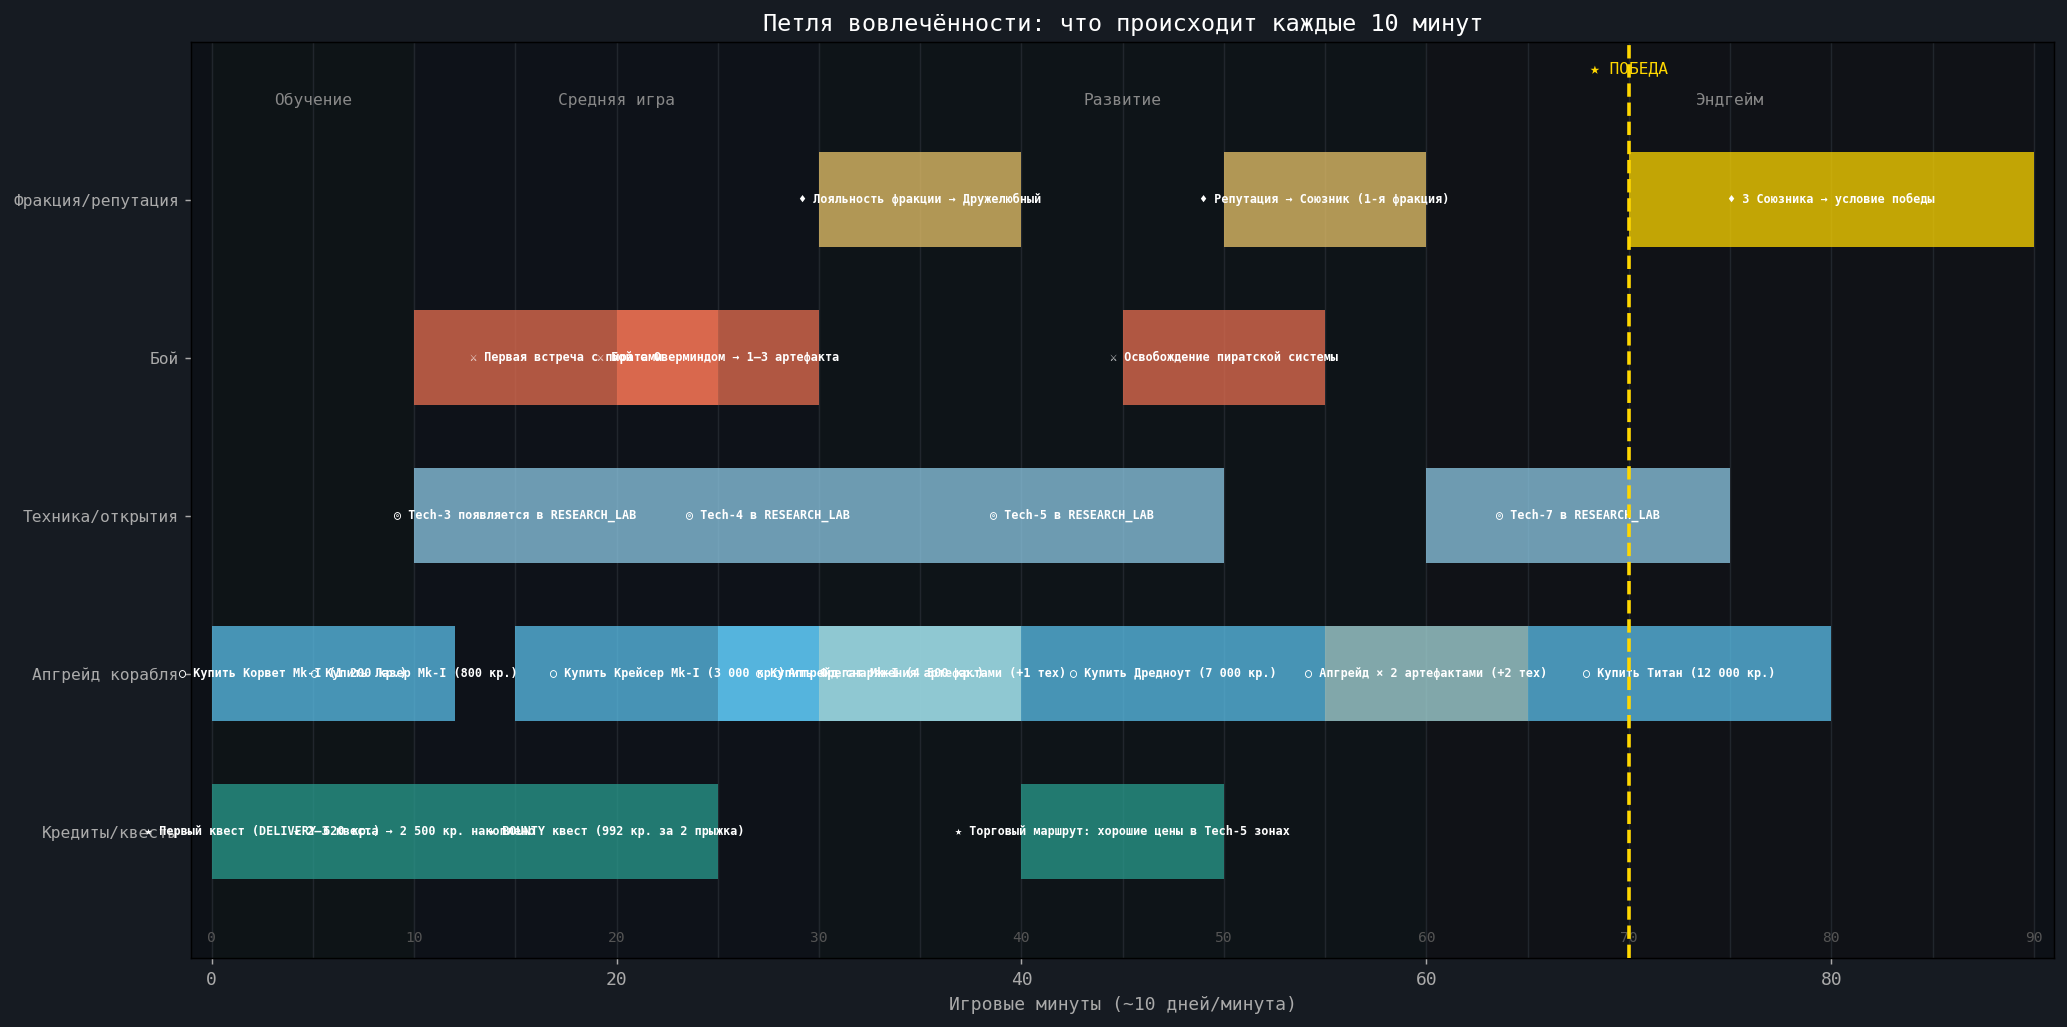

In [9]:
ENGAGEMENT_HOOKS = [
    # (мин_от, мин_до, категория, событие, тип)
    # Типы: 'econ', 'combat', 'explore', 'upgrade', 'faction'
    (0,   5,  'econ',    '★ Первый квест (DELIVERY 620 кр.)',          '#2a9d8f'),
    (0,   8,  'upgrade', '○ Купить Корвет Mk-I (1 200 кр.)',           '#5bc0eb'),
    (5,   15, 'econ',    '★ 2–3 квеста → 2 500 кр. накоплено',        '#2a9d8f'),
    (8,   12, 'upgrade', '○ Купить Лазер Mk-I (800 кр.)',              '#5bc0eb'),
    (10,  20, 'explore', '◎ Tech-3 появляется в RESEARCH_LAB',        '#8ecae6'),
    (10,  25, 'combat',  '⚔ Первая встреча с пиратами',               '#e76f51'),
    (15,  30, 'upgrade', '○ Купить Крейсер Mk-I (3 000 кр.)',          '#5bc0eb'),
    (15,  25, 'econ',    '★ BOUNTY квест (992 кр. за 2 прыжка)',       '#2a9d8f'),
    (20,  35, 'explore', '◎ Tech-4 в RESEARCH_LAB',                   '#8ecae6'),
    (20,  30, 'combat',  '⚔ Бой с Оверминдом → 1–3 артефакта',        '#e76f51'),
    (25,  40, 'upgrade', '○ Купить Фрегат Mk-I (4 500 кр.)',           '#5bc0eb'),
    (30,  40, 'faction', '♦ Лояльность фракции → Дружелюбный',        '#e9c46a'),
    (30,  40, 'upgrade', '○ Апгрейд снаряжения артефактами (+1 тех)',  '#a8dadc'),
    (35,  50, 'explore', '◎ Tech-5 в RESEARCH_LAB',                   '#8ecae6'),
    (40,  50, 'econ',    '★ Торговый маршрут: хорошие цены в Tech-5 зонах', '#2a9d8f'),
    (40,  55, 'upgrade', '○ Купить Дредноут (7 000 кр.)',              '#5bc0eb'),
    (45,  55, 'combat',  '⚔ Освобождение пиратской системы',          '#e76f51'),
    (50,  60, 'faction', '♦ Репутация → Союзник (1-я фракция)',        '#e9c46a'),
    (55,  65, 'upgrade', '○ Апгрейд × 2 артефактами (+2 тех)',         '#a8dadc'),
    (60,  75, 'explore', '◎ Tech-7 в RESEARCH_LAB',                   '#8ecae6'),
    (65,  80, 'upgrade', '○ Купить Титан (12 000 кр.)',                '#5bc0eb'),
    (70,  90, 'faction', '♦ 3 Союзника → условие победы',             '#ffd700'),
]

fig, ax = plt.subplots(figsize=(16, 8))
fig.patch.set_facecolor(FIG)
ax.set_facecolor(BG)

CAT_Y = {'econ': 0, 'upgrade': 1, 'explore': 2, 'combat': 3, 'faction': 4}
CAT_LABEL = {
    'econ':    'Кредиты/квесты',
    'upgrade': 'Апгрейд корабля',
    'explore': 'Техника/открытия',
    'combat':  'Бой',
    'faction': 'Фракция/репутация',
}

for (mfrom, mto, cat, event, col) in ENGAGEMENT_HOOKS:
    y = CAT_Y[cat]
    ax.barh(y, mto - mfrom, left=mfrom, height=0.6, color=col, alpha=0.75, zorder=3)
    ax.text((mfrom + mto) / 2, y, event,
            color='white', fontsize=6.5, ha='center', va='center',
            fontweight='bold', zorder=4)

# Фазы игры
phases = [
    (0,  10, 'Обучение',   '#1a2a1a'),
    (10, 30, 'Средняя игра', '#1a1a2a'),
    (30, 60, 'Развитие',   '#1a2a20'),
    (60, 90, 'Эндгейм',    '#2a1a1a'),
]
for pf, pt, plabel, pcol in phases:
    ax.axvspan(pf, pt, alpha=0.12, color=pcol, zorder=1)
    ax.text((pf + pt)/2, 4.6, plabel, color='#888', fontsize=9, ha='center')

# Сетка по 5 минут
for m in range(0, 91, 5):
    ax.axvline(m, color='#21262d', lw=0.8, zorder=2)
    if m % 10 == 0:
        ax.text(m, -0.7, f'{m}', color='#555', fontsize=8, ha='center')

ax.set_yticks(list(CAT_Y.values()))
ax.set_yticklabels([CAT_LABEL[k] for k in CAT_Y], fontsize=9, color='#ccc')
ax.set_xlabel('Игровые минуты (~10 дней/минута)', color='#aaa', fontsize=10)
ax.set_title('Петля вовлечённости: что происходит каждые 10 минут', color='white', fontsize=13)
ax.set_xlim(-1, 91)
ax.set_ylim(-0.8, 5.0)
ax.tick_params(colors='#aaa')

# Победный маркер
ax.axvline(70, color='#ffd700', lw=2, ls='--', zorder=5)
ax.text(70, 4.8, '★ ПОБЕДА', color='#ffd700', fontsize=9, ha='center')

plt.tight_layout()
plt.savefig('economy_engagement.png', bbox_inches='tight')
plt.show()

## 7. Итог: баланс в цифрах

In [10]:
active_qrate, active_combat = 1/12, 60

print('═' * 58)
print('  БАЛАНС ЭКОНОМИКИ ВАКУУМНЫХ ПРОЙДОХ (после Tasks 1–7)')
print('═' * 58)

print(f'\n  Старт: {STARTING_MONEY} кр.  |  1 игр. минута ≈ 10 дней')
print(f'  Средняя награда за квест: {AVG_REWARD:.0f} кр. (активный микс)')
print(f'  Темп активного игрока: 1 квест / 12 дней + 60 кр./день боёвки')

print('\n  НАКОПЛЕНИЕ КРЕДИТОВ:')
for mins, day in [(10,100),(20,200),(30,300),(45,450),(60,600)]:
    c = credits_at_day(day, active_qrate, active_combat)
    tech_lab  = tech_at_day(day, True)
    tech_norm = tech_at_day(day, False)
    best = best_gear_at_tech(tech_lab)
    best_str = f'{best[0][1]}' if best and best[0] else '—'
    print(f'  {mins:2d} мин (день {day:3d}): {c:7,.0f} кр. | tech {tech_norm}/{tech_lab} | лучший: {best_str}')

print('\n  ДОСТУПНОСТЬ КОРПУСОВ (активный игрок):')
for hull_name, price, tech in [
    ('Корвет Mk-I',  1200, 2),
    ('Крейсер Mk-I', 3000, 3),
    ('Фрегат Mk-I',  4500, 4),
    ('Дредноут',     7000, 5),
    ('Титан',       12000, 7),
]:
    day_avail = (tech - 1) * 50
    for d in range(601):
        if d >= day_avail and credits_at_day(d, active_qrate, active_combat) >= price:
            wait = d - day_avail
            ok = '✓' if wait < 50 else '△' if wait < 100 else '✗'
            print(f'  T{tech} {hull_name:15s} {price:6,}кр. — доступен день {d:3d} ({d//10:2d} мин)  {ok} ждёт {wait} дн.')
            break

print('\n  РЕПУТАЦИЯ (новые пороги):')
for kills, col in [(0,'нет'), (2,'2 убийства'), (5,'5 убийств')]:
    r = kills * KILL_REP_DELTA
    label, _ = rep_label(r)
    print(f'  {col:15s}: реп {r:4d} → {label}')

print()
print('  АРТЕФАКТЫ:')
med1, med2 = np.median(kills_for_upgrade1), np.median(kills_for_upgrade2)
print(f'  +1 тех. апгрейд:  медиана {med1:.0f} убийств Оверминда')
print(f'  +2 тех. апгрейд:  медиана {med2:.0f} убийств Оверминда')

print()
print('  ДИАГНОСТИКА:')
# Есть ли «дыры» — промежутки без целей?
gaps = []
for m in range(0, 91, 10):
    events = [h for h in ENGAGEMENT_HOOKS if h[0] <= m <= h[1]]
    if len(events) < 2:
        gaps.append(m)
if gaps:
    print(f'  ⚠ Минуты без активных целей: {gaps}')
else:
    print('  ✓ Активная цель есть на каждом 10-минутном отрезке')

print('═' * 58)

══════════════════════════════════════════════════════════
  БАЛАНС ЭКОНОМИКИ ВАКУУМНЫХ ПРОЙДОХ (после Tasks 1–7)
══════════════════════════════════════════════════════════

  Старт: 1000 кр.  |  1 игр. минута ≈ 10 дней
  Средняя награда за квест: 904 кр. (активный микс)
  Темп активного игрока: 1 квест / 12 дней + 60 кр./день боёвки

  НАКОПЛЕНИЕ КРЕДИТОВ:
  10 мин (день 100):  14,534 кр. | tech 2/3 | лучший: Крейсер Mk-I
  20 мин (день 200):  28,067 кр. | tech 3/5 | лучший: Дредноут
  30 мин (день 300):  41,600 кр. | tech 4/7 | лучший: Титан
  45 мин (день 450):  61,901 кр. | tech 5/8 | лучший: Титан
  60 мин (день 600):  82,201 кр. | tech 7/8 | лучший: Титан

  ДОСТУПНОСТЬ КОРПУСОВ (активный игрок):
  T2 Корвет Mk-I      1,200кр. — доступен день  50 ( 5 мин)  ✓ ждёт 0 дн.
  T3 Крейсер Mk-I     3,000кр. — доступен день 100 (10 мин)  ✓ ждёт 0 дн.
  T4 Фрегат Mk-I      4,500кр. — доступен день 150 (15 мин)  ✓ ждёт 0 дн.
  T5 Дредноут         7,000кр. — доступен день 200 (20 мин)  ✓ ждё